# HW4: Stock return model, own backtester, and the S&P 500

Author: Ziang Gao

**Goal.** Predict the 90-day return of US stocks, buy the stocks with the best predictions, and compare the portfolio with $1,000,000 in the S&P 500 total return index (`^SP500TR`).

**Order of work.**
1. Build the data (features and the 90-day target).
2. Validate models on the development years 2010 to 2015 only.
3. Choose the model and the strategy settings on development data only.
4. Run the final test (April 2016 to September 2026) one time.
5. Prove that the accounting and timing are correct.
6. Report the result and the findings.

The backtester is in `backtester.py` and its tests are in `test_backtester.py`. The data helpers are in `hw4_features.py`. Lecture code from `Lectures/modeling/course_data.py` is reused and cited there.

## 1. Setup

This cell imports the code and sets the dates. The three periods follow the assignment. Development is 2010 to 2015. The buffer is January to March 2016, so that early targets can finish. The final test starts on the first session in April 2016.

In [1]:
import sys, warnings, pickle, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import backtester as bt
import hw4_features as h
import course_data as cd  # lecture code, reused and cited
plt.rcParams["figure.figsize"] = (10, 5)

END = "2026-09-30"
FIRST_TEST_DAY = "2016-04-01"
DEV_START, DEV_END = "2010-01-01", "2015-12-31"
INITIAL_CASH, FEE_BPS = 1_000_000, 5

## 2. Build the data

`build_panel` makes one row for each stock on each signal date. A signal date is an after-close date when we make a prediction. I keep every 5th market session, because the strategy enters every 5 sessions.

**Columns**
- `date`: the signal date (the prediction is made after this close).
- `symbol`, `sector`: the stock and its sector label.
- `universe_rank`: rank in the quarterly top 2,000 list that was known on this date.
- `entry_date`: the next session. We buy at its close.
- `label_end`: the date when the 90-day holding period ends.
- `target`: the return from the entry close to the exit close (adjusted prices).
- Features. Price features: `momentum_21`, `momentum_63`, `momentum_252_21`, `volatility_63`, `drawdown_252`. Financial features from the latest statement that was already filed: `net_margin`, `operating_roa`, `debt_to_assets`, `cash_to_assets`, `fcf_to_assets`, `accruals_to_assets`, `filing_age_days`. My own features: `mom63_vs_sector` and `mom21_vs_sector` (momentum minus the same-day median of the sector).

Only rows that belong to that quarter's universe and have 63 days of price history are kept. I do not remove stocks that later disappear. The build takes about 30 seconds. The result is saved in `cache/` (not committed to Git).

In [2]:
CACHE = Path("cache/full_panel.pkl")
if CACHE.exists():
    data = pickle.load(open(CACHE, "rb"))
else:
    t0 = time.time()
    panel, wide, bench = h.build_panel(h.DB_FULL, end=END, first_test_day=FIRST_TEST_DAY, verbose=False)
    data = {"panel": panel, "wide": wide, "bench": bench}
    CACHE.parent.mkdir(exist_ok=True)
    pickle.dump(data, open(CACHE, "wb"), protocol=4)
    print("built in", round(time.time() - t0), "seconds")
panel, wide, bench = data["panel"], data["wide"], data["bench"]
calendar = wide.index
print("panel", panel.shape, "| wide prices", wide.shape, "| dates", panel.date.min().date(), "to", panel.date.max().date())
display(panel.head(3))

panel (1664375, 21) | wide prices (6726, 3849) | dates 2010-01-04 to 2026-09-23


,date,symbol,sector,universe_rank,entry_date,label_end,target,momentum_21,momentum_63,momentum_252_21,...,drawdown_252,net_margin,operating_roa,debt_to_assets,cash_to_assets,fcf_to_assets,accruals_to_assets,filing_age_days,mom63_vs_sector,mom21_vs_sector
0,2010-01-04,A,Healthcare,258.0,2010-01-05,2010-04-05,0.124553,0.061093,0.189904,0.816943,...,0.000000,0.021422,0.009327,0.381634,0.325670,0.024041,-0.024698,13.0,0.135051,0.013702
1,2010-01-04,AAIC,Real Estate,1521.0,2010-01-05,2010-04-05,0.144010,0.165681,0.751112,2.072728,...,-0.014999,1.843004,0.064096,0.059352,0.046939,-0.013984,0.163766,55.0,0.644164,0.123401
2,2010-01-04,AAL,Industrials,1084.0,2010-01-05,2010-04-05,0.342749,0.201511,0.106729,-0.526818,...,-0.501567,-0.070021,-0.007533,0.588879,0.006640,-0.019919,-0.013474,74.0,0.001369,0.141411


## 3. Checks on the data

Three checks before I trust the data.

1. **Universe size.** About 2,000 eligible stocks per signal date is expected.
2. **Look-ahead test.** I cut the prices at 2013-12-31 and recompute the price features. They must be identical to the features from the full history on the same dates. A difference of 0 means that a feature never uses a future price.
3. **Target outliers.** The data guide warns about bad prices. The table shows extreme targets. A few are data errors (for example, a price that collapses to almost zero and then recovers). Such rows can dominate a model and can fool a stock picker.

In [3]:
print("eligible stocks per signal date:", panel.groupby("date").size().describe().round(0)[["min", "mean", "max"]].to_dict())
diff, n = h.prefix_check(h.DB_FULL, h.all_symbols(h.DB_FULL)[:40], "2013-12-31", END)
print(f"look-ahead test: largest difference {diff} over {n:,} stock-date rows")
t = panel.target.dropna()
print("target quantiles:", t.quantile([0, .001, .01, .5, .99, .999, 1]).round(3).to_dict())
print("targets above +500%:", int((t > 5).sum()), "of", f"{len(t):,}")
display(panel.loc[panel.target > 5].sort_values("target", ascending=False)[["date", "symbol", "target", "momentum_63", "volatility_63"]].head(5))

eligible stocks per signal date: {'min': 1861.0, 'mean': 1977.0, 'max': 1999.0}


look-ahead test: largest difference 0.0 over 70,545 stock-date rows


target quantiles: {0.0: -1.0, 0.001: -0.747, 0.01: -0.482, 0.5: 0.025, 0.99: 0.696, 0.999: 1.714, 1.0: 139312.984}
targets above +500%: 164 of 1,633,261


,date,symbol,target,momentum_63,volatility_63
200493,2012-01-26,AAM,139312.984169,-0.999992,2.019551
226175,2012-04-30,AAM,106847.563969,-0.999992,2.012512
121748,2011-04-11,AAM,44185.046512,-0.999980,75531.728389
104285,2011-02-04,AAM,32675.518883,-0.999976,2.009278
9203,2010-02-02,VBIV,826.691133,-0.164773,1.159169


## 4. Screen out extreme price behavior

The rule uses only past prices, so it can be used at the time of the decision. I skip a stock when its 63-day volatility is above 300% a year, when its 63-day return is below -80% or above +500%, or when it is more than 95% below its 252-day high. The same rule applies to training and to trading. Real distressed stocks are also removed, which is a cost of this rule. I state this as a limit.

In [4]:
keep = h.screen_mask(panel)
print(f"screened out {1 - keep.mean():.1%} of rows; targets above +500%: {int((panel.target > 5).sum())} -> {int((panel[keep].target > 5).sum())}")
panel = panel[keep].reset_index(drop=True)
dev = panel[panel.date.between(DEV_START, DEV_END)].reset_index(drop=True)
print("development rows:", f"{len(dev):,}")

screened out 3.2% of rows; targets above +500%: 164 -> 137


development rows: 573,617


## 5. Validation (development years only)

**Folds.** I validate on 2013, 2014, and 2015. For each year, the model trains on rows from 2010 until just before that year, and only on rows whose 90-day outcome already ended before the first validation signal (`date_folds` from the lecture checks this).

**Target clipping.** Targets can be extreme, so for training I clip the target at the 0.5% and 99.5% quantiles of the training rows. The test rows are never used for this.

**Metric.** The strategy only needs a good ranking inside each day. So the main metric is the **rank IC**: on each date, the Spearman correlation between the prediction and the real return, then the mean over dates. Zero means no skill. A value of 0.02 to 0.05 is already good in practice.

**Choice.** I compare 5 feature sets and 2 models (Ridge and a small gradient boosting tree model). The rule is fixed in advance: the best mean rank IC over the three folds. With only 3 folds and about 50 dates per fold, the noise in the mean IC is large (about 0.02), so differences are weak evidence.

In [5]:
folds = cd.date_folds(dev, validation_years=(2013, 2014, 2015))
for (tr, va), year in zip(folds, (2013, 2014, 2015)):
    print(year, "train rows", f"{len(tr):,}", "| last training outcome ends", dev.iloc[tr].label_end.max().date(),
          "| first validation signal", dev.iloc[va].date.min().date())

mom = ["momentum_21", "momentum_63", "momentum_252_21", "mom63_vs_sector", "mom21_vs_sector"]
fin = ["net_margin", "operating_roa", "debt_to_assets", "cash_to_assets", "fcf_to_assets", "accruals_to_assets", "filing_age_days"]
FEATURE_SETS = {"A momentum": mom, "B momentum + drawdown": mom + ["drawdown_252"], "C momentum + financials": mom + fin,
                "D all but volatility": [f for f in h.NUMERIC if f != "volatility_63"], "E all features": h.NUMERIC}
MODELS = {"Ridge": lambda: Ridge(alpha=100),
          "HGB": lambda: HistGradientBoostingRegressor(max_depth=2, learning_rate=0.03, max_iter=150, min_samples_leaf=500, random_state=0)}

def fit_clipped(model, feats, frame):
    y = frame.target
    lo, hi = y.quantile([0.005, 0.995])
    return cd.make_pipeline(model, feats, include_sector=False).fit(frame[feats], y.clip(lo, hi))

rows = []
for fs_name, feats in FEATURE_SETS.items():
    for m_name, make in MODELS.items():
        for (tr, va), year in zip(folds, (2013, 2014, 2015)):
            fitted = fit_clipped(make(), feats, dev.iloc[tr])
            met = cd.prediction_metrics(dev.iloc[va], fitted.predict(dev.iloc[va][feats]))
            rows.append({"feature set": fs_name, "model": m_name, "year": year, "rank IC": met.mean_daily_rank_IC})
ic = pd.DataFrame(rows).pivot_table(index=["feature set", "model"], columns="year", values="rank IC")
ic["mean"] = ic.mean(axis=1)
display(ic.sort_values("mean", ascending=False).round(4))
CHOSEN = ic["mean"].idxmax()
print("chosen by best mean rank IC:", CHOSEN)

2013 train rows 262,154 | last training outcome ends 2012-12-27 | first validation signal 2013-01-03
2014 train rows 359,775 | last training outcome ends 2014-01-06 | first validation signal 2014-01-08
2015 train rows 454,912 | last training outcome ends 2015-01-02 | first validation signal 2015-01-06


year                             2013    2014    2015    mean
feature set             model                                
C momentum + financials Ridge -0.0254  0.0691  0.0023  0.0153
                        HGB   -0.0305  0.0441 -0.0119  0.0006
A momentum              Ridge -0.0155  0.0090 -0.0291 -0.0119
D all but volatility    HGB   -0.0213  0.0278 -0.0518 -0.0151
                        Ridge -0.0170  0.0343 -0.0628 -0.0152
E all features          Ridge -0.0071  0.0222 -0.0638 -0.0162
                        HGB   -0.0069  0.0156 -0.0745 -0.0219
A momentum              HGB   -0.0369 -0.0146 -0.0667 -0.0394
B momentum + drawdown   Ridge -0.0020 -0.0281 -0.0914 -0.0405
                        HGB   -0.0183 -0.0584 -0.1152 -0.0640

chosen by best mean rank IC: ('C momentum + financials', 'Ridge')


## 6. Choose the strategy settings (development years only)

The strategy buys the top `top_n` stocks every 5 sessions. One entry spends a share (`cohort_fraction`) of the portfolio value. No stock may be above 5% of the portfolio value.

To choose `top_n` and `cohort_fraction`, I need out-of-sample scores in the development period. I get them from the three validation folds above. Each year uses scores from a model that trained only on earlier outcomes. Then I backtest 2013 to 2015 for 6 settings and pick the best Sharpe ratio. I then freeze the settings. This choice uses 3 years only, so it can be over-fitted, and I treat it with caution.

In [6]:
fs_name, m_name = CHOSEN
feats = FEATURE_SETS[fs_name]

def to_wide(frame, score):
    return pd.DataFrame({"date": frame.date, "symbol": frame.symbol, "score": np.asarray(score)}).pivot(index="date", columns="symbol", values="score")

parts = []
for (tr, va), year in zip(folds, (2013, 2014, 2015)):
    fitted = fit_clipped(MODELS[m_name](), feats, dev.iloc[tr])
    year_rows = dev[dev.date.between(f"{year}-01-01", f"{year}-12-31")]
    parts.append(to_wide(year_rows, fitted.predict(year_rows[feats])))
dev_scores = pd.concat(parts).sort_index()

anchors = h.signal_dates(calendar, FIRST_TEST_DAY)
first_signal = anchors[anchors >= pd.Timestamp("2012-12-31")][0]
dev_start = calendar[calendar.searchsorted(first_signal, side="right")]
cfg = bt.Config(initial_cash=INITIAL_CASH, fee_bps=FEE_BPS)
bench_dev = bench

grid = []
for top_n in (10, 20, 40):
    for cohort in (0.06, 0.10):
        strat = bt.TopNStrategy(top_n=top_n, cohort_fraction=cohort, entry_every=5, max_name_weight=0.05)
        res = bt.run_backtest(wide, dev_scores, strat, dev_start, DEV_END, cfg)
        perf = bt.performance(res.nav.nav)
        grid.append({"top_n": top_n, "cohort_fraction": cohort, "final_value": perf.final_value, "cagr": perf.cagr,
                     "max_drawdown": perf.max_drawdown, "sharpe": perf.sharpe})
grid = pd.DataFrame(grid).sort_values("sharpe", ascending=False)
display(grid.round(4))
best = grid.iloc[0]
TOP_N, COHORT = int(best.top_n), float(best.cohort_fraction)
ref = bt.performance(bt.benchmark_curve(bench, res.nav.index, INITIAL_CASH))
print(f"chosen: top_n={TOP_N}, cohort_fraction={COHORT}. S&P 500 over the same development window: CAGR {ref.cagr:.3f}, Sharpe {ref.sharpe:.2f}")

,top_n,cohort_fraction,final_value,cagr,max_drawdown,sharpe
1,10,0.10,1.550462e+06,0.1580,-0.2062,0.7838
0,10,0.06,1.402865e+06,0.1199,-0.1697,0.7503
3,20,0.10,1.542903e+06,0.1561,-0.2376,0.7308
2,20,0.06,1.391760e+06,0.1169,-0.1818,0.6817
5,40,0.10,1.370589e+06,0.1112,-0.2153,0.5777
4,40,0.06,1.276658e+06,0.0851,-0.1727,0.5294


chosen: top_n=10, cohort_fraction=0.1. S&P 500 over the same development window: CAGR 0.141, Sharpe 0.94


## 7. Fit the final model and score the test period

The final model fits one time. The fit date is the last signal before the first test entry. I train only on development signals (up to 2015-12-31) whose 90-day outcome ended **before** the fit date. The buffer months (January to March 2016) let these outcomes finish. The model then stays fixed for the whole test (I do not retrain).

The table `test_scores` has one row per signal date and one column per stock. An empty value means that the stock is not eligible on that date.

In [7]:
FIT_DATE = calendar[calendar.searchsorted(pd.Timestamp(FIRST_TEST_DAY)) - 1]
train = dev[(dev.label_end < FIT_DATE) & dev.target.notna()]
assert train.date.max() <= pd.Timestamp(DEV_END) and train.label_end.max() < FIT_DATE
print("fit date", FIT_DATE.date(), "| training rows", f"{len(train):,}", "| last signal", train.date.max().date(),
      "| last outcome ends", train.label_end.max().date())
final_model = fit_clipped(MODELS[m_name](), feats, train)
test_rows = panel[panel.date >= FIT_DATE]
test_scores = to_wide(test_rows, final_model.predict(test_rows[feats]))
print("test score table", test_scores.shape, "| first signal", test_scores.index.min().date(), "| last signal", test_scores.index.max().date())
if m_name == "Ridge":
    coefs = pd.Series(final_model.named_steps["model"].coef_[:len(feats)], index=feats)
    display(coefs.sort_values().round(5).to_frame("Ridge coefficient (scaled features)"))

fit date 2016-03-31 | training rows 573,544 | last signal 2015-12-24 | last outcome ends 2016-03-28


test score table (528, 3320) | first signal 2016-03-31 | last signal 2026-09-23


,Ridge coefficient (scaled features)
momentum_21,-0.00413
momentum_63,-0.00250
accruals_to_assets,-0.00170
cash_to_assets,-0.00148
net_margin,0.00001
debt_to_assets,0.00014
momentum_252_21,0.00051
mom63_vs_sector,0.00060
fcf_to_assets,0.00071
filing_age_days,0.00290


## 8. Final test and comparison with the S&P 500

One run only. Settings are frozen from the development years. The benchmark invests $1,000,000 at the first test close and holds to September 30, 2026. Metrics: final value (cash and open positions), CAGR, maximum drawdown, and the Sharpe ratio (daily returns, 2% annual risk-free rate).

,strategy,S&P 500 TR
final_value,3.139813e+06,4.402747e+06
cagr,1.151000e-01,1.516000e-01
max_drawdown,-3.034000e-01,-3.379000e-01
sharpe,5.847000e-01,7.725000e-01


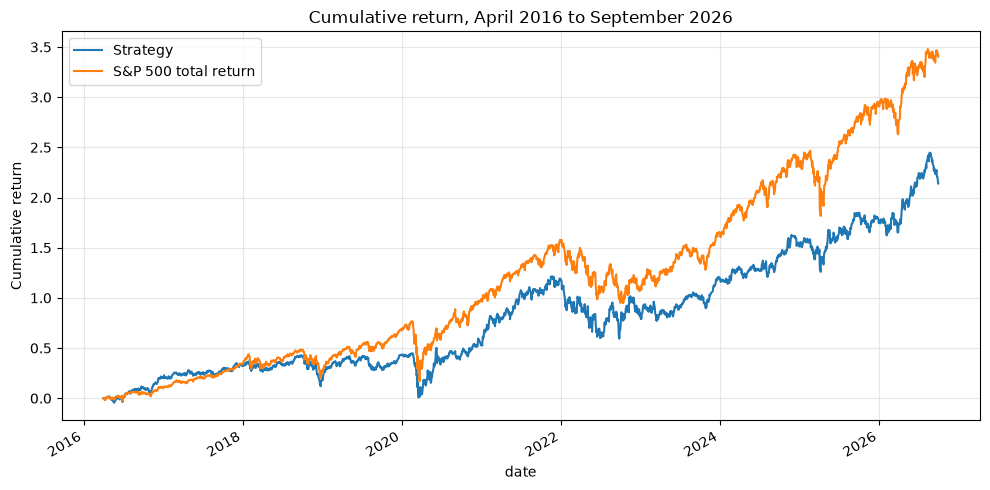

Strategy minus benchmark final value: -1,262,934 dollars; CAGR difference -3.65%


In [8]:
strategy = bt.TopNStrategy(top_n=TOP_N, cohort_fraction=COHORT, entry_every=5, max_name_weight=0.05)
test_start = calendar[calendar.searchsorted(pd.Timestamp(FIRST_TEST_DAY))]
result = bt.run_backtest(wide, test_scores, strategy, test_start, END, cfg)
summary = bt.compare(result, bench, cfg)
display(summary.round(4))
bench_curve = bt.benchmark_curve(bench, result.nav.index, INITIAL_CASH)
fig, ax = plt.subplots()
(result.nav.nav / INITIAL_CASH - 1).plot(ax=ax, label="Strategy")
(bench_curve / INITIAL_CASH - 1).plot(ax=ax, label="S&P 500 total return")
ax.set_title("Cumulative return, April 2016 to September 2026"); ax.set_ylabel("Cumulative return"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("cumulative_return.png", dpi=130); plt.show()
diff_final = summary.loc["final_value", "strategy"] - summary.loc["final_value", "S&P 500 TR"]
print(f"Strategy minus benchmark final value: {diff_final:,.0f} dollars; CAGR difference {summary.loc['cagr','strategy'] - summary.loc['cagr','S&P 500 TR']:+.2%}")
summary.to_csv("results_summary.csv")

## 9. Proof that the accounting and timing are correct

1. `audit` runs six checks on the books (NAV = cash + holdings, cash = start cash + trade cash flows, cash never negative, signal before buy, sale at or after day 90, every lot sold once or open at the end).
2. **A hand check of one purchase.** I recompute the entry day, the price, the units, the exit day, and the profit from the raw price table, not from the backtester.
3. **An independent NAV.** For three random days I rebuild NAV from the trade log and the price table.
4. The 18 tests in `test_backtester.py` prove the rules on small markets with answers that can be checked by hand.

In [9]:
for name, ok in bt.audit(result, cfg).items():
    print("PASS" if ok else "FAIL", "-", name)

trades = result.trades
buy = trades[trades.side == "BUY"].iloc[0]
entry = calendar[calendar.searchsorted(buy.signal_date, side="right")]
px_entry = wide.loc[entry, buy.symbol]
due = entry + pd.Timedelta(days=90)
quotes = wide[buy.symbol].dropna()
exit_day = quotes.index[quotes.index.searchsorted(due)]
px_exit = quotes.loc[exit_day]
fee = FEE_BPS / 10_000
sale = trades[(trades.lot_id == buy.lot_id) & (trades.side == "SELL")].iloc[0]
units = buy.units
entry_fee = units * px_entry * fee
pnl = units * (px_exit - px_entry) - entry_fee - units * px_exit * fee
assert entry == buy.date and np.isclose(px_entry, buy.price) and exit_day == sale.date and np.isclose(px_exit, sale.price)
assert np.isclose(pnl, sale.realized_pnl) and np.isclose(units * px_entry * (1 + fee), -buy.cash_change)
print(f"Hand check of lot {buy.lot_id} ({buy.symbol}): signal {buy.signal_date.date()}, entry {entry.date()} at {px_entry:.4f}, exit {exit_day.date()} at {px_exit:.4f}, profit {pnl:,.2f} (matches the log)")

def independent_nav(day):
    day = pd.Timestamp(day)
    done = trades[trades.date <= day]
    cash = INITIAL_CASH + done.cash_change.sum()
    bought = done[done.side == "BUY"].set_index("lot_id")
    sold = set(done[done.side == "SELL"].lot_id)
    value = sum(r.units * wide[r.symbol].loc[:day].ffill().iloc[-1] for lot_id, r in bought.iterrows() if lot_id not in sold)
    return cash + value

for day in np.random.default_rng(1).choice(result.nav.index[1:], 3, replace=False):
    mine, theirs = independent_nav(day), result.nav.nav.loc[day]
    assert np.isclose(mine, theirs, rtol=1e-9), (day, mine, theirs)
    print(f"NAV on {pd.Timestamp(day).date()}: rebuilt {mine:,.2f} vs backtester {theirs:,.2f}")

PASS - nav = cash + holdings
PASS - cash = start cash + all trade cash flows
PASS - cash never negative (no borrowing, no double spend)
PASS - every buy comes after its signal date
PASS - every sale is on or after 90 calendar days
PASS - every lot is sold once or still open at the end
Hand check of lot 0 (DOC): signal 2016-03-31, entry 2016-04-01 at 21.1600, exit 2016-06-30 at 23.3300, profit 1,014.50 (matches the log)
NAV on 2021-08-11: rebuilt 2,072,717.81 vs backtester 2,072,717.81
NAV on 2021-03-17: rebuilt 1,831,672.67 vs backtester 1,831,672.67
NAV on 2024-03-04: rebuilt 2,277,801.25 vs backtester 2,277,801.25


## 10. What the portfolio did (diagnostics and years)

The first table shows how the portfolio was run. `average_cash_share` is the average share of NAV that sat in cash. The events table lists missing prices (no sale or purchase is invented). The second table shows the return in each calendar year for both portfolios.

In [10]:
h_ = result.nav.iloc[1:]
diag = pd.Series({"trades": len(result.trades), "open_lots_at_end": len(result.open_lots),
                  "average_cash_share": (h_.cash / h_.nav).mean(), "total_fees": h_.fees.sum(),
                  "traded_over_average_nav": h_.traded.sum() / h_.nav.mean(), "stale_mark_days": int(h_.stale_marks.sum())})
display(diag.to_frame("value").round(4))
display(result.events.event.value_counts().to_frame("count") if len(result.events) else "No missing-quote events")

def yearly(curve):
    last = curve.groupby(curve.index.year).last()
    return last / last.shift(1).fillna(INITIAL_CASH) - 1
yr = pd.DataFrame({"strategy": yearly(result.nav.nav), "S&P 500 TR": yearly(bench_curve)})
yr["difference"] = yr.strategy - yr["S&P 500 TR"]
display(yr.round(3))

,value
trades,8897.0000
open_lots_at_end,157.0000
average_cash_share,0.1242
total_fees,61538.2294
traded_over_average_nav,67.7676
stale_mark_days,7540.0000


,count
event,
sale_delayed_no_quote,34253
stale_mark_over_limit,11
buy_skipped_no_quote,2


,strategy,S&P 500 TR,difference
date,,,
2016,0.201,0.098,0.103
2017,0.099,0.218,-0.120
2018,-0.107,-0.044,-0.063
2019,0.212,0.315,-0.103
2020,0.070,0.184,-0.114
2021,0.424,0.287,0.137
2022,-0.151,-0.181,0.030
2023,0.188,0.263,-0.075
2024,0.144,0.250,-0.106


### Stocks that stop trading while we hold them

The events table shows many `sale_delayed_no_quote` days. A stock can stop trading while a lot is open (for example, after a merger or a delisting). The data has no payout for such cases. The backtester never invents a price. It keeps the last known price for the value and waits for a new quote. The next cell measures how much this matters. If such stocks were really worth less than their last price, the true result would be lower.

In [11]:
sells = result.trades[result.trades.side == "SELL"]
delay_days = (sells.date - sells.due_date).dt.days
print(f"sales made more than 10 days after the due date: {(delay_days > 10).sum()} of {len(sells)} ({(delay_days > 10).mean():.2%}); longest delay {delay_days.max()} days")
late = result.open_lots[result.open_lots.due_date < pd.Timestamp(END)].copy()
last_px = wide.ffill().iloc[-1]
late["value"] = late.units * late.symbol.map(last_px)
last_quote = late.symbol.map(lambda s: wide[s].last_valid_index())
late["last_quote"] = last_quote
final_nav = result.nav.nav.iloc[-1]
print(f"lots still open and past due at the end: {len(late)}, value {late.value.sum():,.0f} ({late.value.sum() / final_nav:.2%} of final NAV)")
display(late.sort_values("value", ascending=False)[["symbol", "entry_date", "due_date", "last_quote", "value"]].head(6))
years = (result.nav.index[-1] - result.nav.index[0]).days / 365.25
stress_final = final_nav - late.value.sum()
print(f"Stress test (not the reported result): if these lots were worth zero, final value would be {stress_final:,.0f} and CAGR {(stress_final / INITIAL_CASH) ** (1 / years) - 1:.2%}, against the reported {summary.loc['cagr', 'strategy']:.2%}")

sales made more than 10 days after the due date: 0 of 4370 (0.00%); longest delay 2 days
lots still open and past due at the end: 42, value 664,432 (21.16% of final NAV)


,symbol,entry_date,due_date,last_quote,value
41,VSCO,2026-05-22,2026-08-20,2026-07-13,41653.258481
31,SIX,2024-04-04,2024-07-03,2024-07-01,25360.366595
37,SBBA,2024-12-12,2025-03-12,2025-02-28,24928.693262
32,SIX,2024-04-11,2024-07-10,2024-07-01,24372.476186
40,HOUS,2025-12-29,2026-03-29,2026-01-08,21584.298330
30,OXSQL,2023-12-21,2024-03-20,2023-12-21,21319.518117


Stress test (not the reported result): if these lots were worth zero, final value would be 2,475,381 and CAGR 9.02%, against the reported 11.51%


## 11. Does the model add anything? Baselines and costs

These runs use the same backtester and the same strategy settings. They are for understanding only. I did not use them to change the model.

- **Random scores.** If a random ranking performs as well as the model, the model has no skill.
- **Plain momentum.** Rank by the 12-month-minus-1-month return (`momentum_252_21`) with no model.
- **Higher cost.** The model with 25 basis points per side instead of 5.

In [12]:
def run(scores, fee=FEE_BPS):
    c = bt.Config(initial_cash=INITIAL_CASH, fee_bps=fee)
    return bt.compare(bt.run_backtest(wide, scores, strategy, test_start, END, c), bench, c)["strategy"]

rng = np.random.default_rng(0)
random_scores = to_wide(test_rows, rng.random(len(test_rows)))
mom_scores = to_wide(test_rows, test_rows.momentum_252_21)
table = pd.DataFrame({"Model (chosen)": summary["strategy"], "Random scores": run(random_scores),
                      "Plain momentum": run(mom_scores), "Model, fee 25 bps": run(test_scores, 25),
                      "S&P 500 TR": summary["S&P 500 TR"]})
display(table.round(4))
table.to_csv("results_baselines.csv")

,Model (chosen),Random scores,Plain momentum,"Model, fee 25 bps",S&P 500 TR
final_value,3.139813e+06,2.681809e+06,4.539336e+06,2.736709e+06,4.402747e+06
cagr,1.151000e-01,9.850000e-02,1.550000e-01,1.006000e-01,1.516000e-01
max_drawdown,-3.034000e-01,-4.078000e-01,-3.826000e-01,-3.074000e-01,-3.379000e-01
sharpe,5.847000e-01,4.832000e-01,5.724000e-01,5.126000e-01,7.725000e-01


## 12. Findings

### Did I beat the S&P 500?

No. The strategy ended with $3,139,813. The S&P 500 total return index ended with $4,402,747. The strategy is behind by $1,262,934. Its CAGR is 11.5% a year, against 15.2% for the index (3.7 points lower). Its maximum drawdown is smaller (-30.3% against -33.8%), but its Sharpe ratio is lower (0.58 against 0.77). The strategy did better than the index in only 4 of the 11 calendar years (2016, 2021, 2022, and part of 2026).

### Why this happened

- **The signal is weak.** On the development years, the best model had a mean rank IC of only 0.015, and it was negative in 2013. With 3 validation years, this is about the size of the noise. Models with all features did worse, and the volatility feature changed sign between 2013 and 2015. So I cannot show that the model has real skill.
- **The model adds a little over random picks, but not over plain momentum.** With random scores the same strategy earned a CAGR of 9.9%. The model earned 11.5%. Plain 12-month momentum earned 15.5%, close to the index. I ran these baselines after the test, only to understand the result. I did not use them to choose anything. Choosing plain momentum now would use the test period for selection, so I report it as a finding and not as my strategy. A single random run also has no error bar.
- **Concentration.** Each entry buys only 10 stocks out of about 2,000. A few stocks can move the result a lot. The stocks are often small, which adds risk.
- **Costs and cash.** Fees at 5 basis points per side cost $61,538 in total. At 25 basis points the CAGR falls to 10.1%. On average 12% of the portfolio sat in cash with no interest.

### Risks taken

The portfolio fell by 30% at its worst point. It holds few stocks at a time, many of them small. The model was trained on 2010 to 2015 and was never updated in the next ten years, so it can go out of date. The strategy settings were chosen on three development years. Even in those years, the best setting had a lower Sharpe ratio than the index (0.78 against 0.94).

### Main limits of this analysis

- **Stocks that stop trading.** At the end, 42 lots were past their 90-day due date and still open. They are 21% of the final portfolio value ($664,432). Their stocks have no quote after a certain date (for example, after a merger or a delisting). The data has no payout for these cases, so I value them at their last known price and never invent a sale. If they were worth zero, the final value would be $2,475,381 and the CAGR 9.0%. The true result is unknown. This is the largest limit.
- **Bad prices.** Some adjusted prices are wrong (for example, a stock that drops 99.99% and then returns 100,000%). I removed 3.2% of rows with extreme recent price behavior. This also removes some real distressed stocks.
- **Financial data.** The data holds the latest vendor values, not the first published numbers. Restatements can leak into the past.
- **Universe.** The quarterly top 2,000 list uses a price times shares ranking. The source can have inconsistent units, so the ranking is approximate. Share classes count separately.
- **Selection noise.** I compared 10 model and feature combinations on 3 folds. The best one is likely lucky.
- **Trading model.** Trades fill at the closing price. There is no spread, no price impact, and no limit on volume.
- **One path.** There is one test run. I did not test how much the result changes with other random choices.

### Ideas that did not work

- The model with all features and the tree model (gradient boosting) did worse than Ridge on the validation years.
- Adding the drawdown feature made the validation rank IC clearly worse.

### What I would try next

1. Retrain the model every quarter, using only outcomes that have ended, and test it on the development years first.
2. Validate on more years (2011 to 2015) and on more than one split, so the choice is less noisy.
3. Handle stocks that stop trading with a clear rule, for example a haircut, and report both results.
4. Add size and liquidity information, and test a rank-based target.
5. Test whether more stocks in each entry and lower turnover improve the Sharpe ratio.

### AI assistance

Claude, an AI assistant from Anthropic, helped write the backtester, the tests, the helper module, and this notebook. The lecture functions in `Lectures/modeling/course_data.py` are reused and cited in `hw4_features.py`. I used the results above only as reported by the code.